#Odometry localization, trajectory "78"

In [13]:
from google.colab import files
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

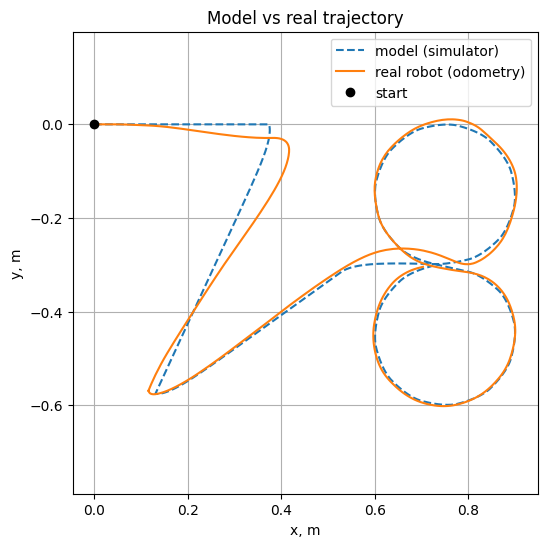

In [14]:
x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)

plt.figure(figsize=(6, 6))
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.plot(0, 0, 'ko', label='start')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, m'); plt.ylabel('y, m')
plt.title('Model vs real trajectory')
plt.show()

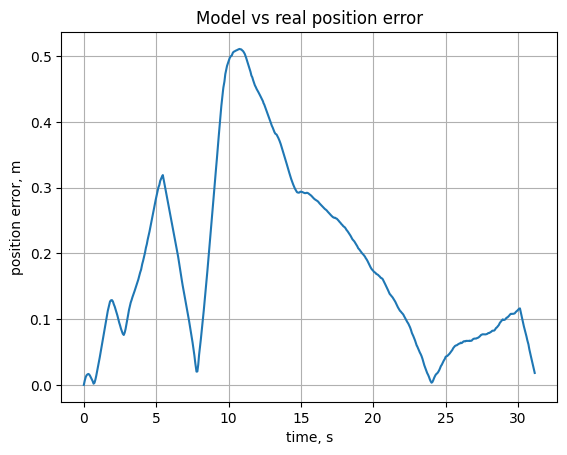

Final odometry error (sim vs real): 0.018 m
Max error: 0.511 m


In [15]:
# 2. Error over time
t_s, t_r = t_s - t_s[0], t_r - t_r[0]
xs_i = np.interp(t_r, t_s, x_s)
ys_i = np.interp(t_r, t_s, y_s)
err = np.hypot(x_r - xs_i, y_r - ys_i)

plt.plot(t_r / 1000, err)
plt.xlabel('time, s'); plt.ylabel('position error, m'); plt.grid(True)
plt.title('Model vs real position error')
plt.show()

print(f'Final odometry error (sim vs real): {err[-1]:.3f} m')
print(f'Max error: {err.max():.3f} m')

In [16]:
# 3. Difference between real robot and simulator end points
print('odometry end point:', x_r[-1], y_r[-1])
print('end point in simulator :', x_s[-1], y_s[-1])
print(f'odometry vs reality: {np.hypot(x_r[-1]-x_s[-1], y_r[-1]-y_s[-1]):.3f} m')

odometry end point: 0.7028707154879433 -0.3045276724117788
end point in simulator : 0.7210218823613592 -0.30321252634328455
odometry vs reality: 0.018 m
